# Exploratory Data Analysis

## Import packages
Dependency Specification: pandas==3.0.5, duckdb==1.5.6

In [1]:
import pandas as pd
import duckdb
import seaborn as sns
import matplotlib.pyplot as plt

from utils import *

## Load Data
Load data and select features with an SQL query through the duckdb.

In [2]:
year_selected = "2026" # temporarily hardcoded df year

In [3]:
con = duckdb.connect("lol_predictors.duckdb")

df = con.execute(f"SELECT * FROM df_{year_selected}").df()

con.close()

### Data Overview

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 115032 entries, 0 to 115031
Data columns (total 63 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   gameid            115032 non-null  str    
 1   league            115032 non-null  str    
 2   split             95772 non-null   str    
 3   date              115032 non-null  str    
 4   side              115032 non-null  str    
 5   position          115032 non-null  str    
 6   playername        95860 non-null   str    
 7   teamname          115032 non-null  str    
 8   teamid            111786 non-null  str    
 9   doublekills       114972 non-null  float64
 10  triplekills       114972 non-null  float64
 11  quadrakills       114924 non-null  float64
 12  pentakills        114924 non-null  float64
 13  firstbloodkill    95780 non-null   float64
 14  firstbloodassist  95770 non-null   float64
 15  firstbloodvictim  95770 non-null   float64
 16  wardskilled       115032 non-nu

In [5]:
df.shape

(115032, 63)

In [6]:
df.describe()

,doublekills,triplekills,quadrakills,pentakills,firstbloodkill,firstbloodassist,firstbloodvictim,wardskilled,visionscore,result,...,opp_killsat25,opp_deathsat25,golddiffat10,xpdiffat10,golddiffat15,xpdiffat15,golddiffat20,xpdiffat20,golddiffat25,xpdiffat25
count,114972.00,114972.00,114924.00,114924.00,95780.00,95770.00,95770.00,115032.00,115032.00,115032.00,...,106548.00,106548.00,114864.00,114864.00,114876.00,114876.00,114564.00,114564.00,106548.00,106548.00
mean,0.58,0.10,0.02,0.00,0.10,0.12,0.10,14.24,94.06,0.50,...,3.65,3.66,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
std,1.07,0.35,0.13,0.06,0.30,0.33,0.30,15.41,97.63,0.50,...,4.57,4.39,818.65,639.95,1581.97,1324.36,2466.48,2089.61,3313.58,3506.94
min,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,...,0.00,0.00,-8762.00,-6305.00,-14704.00,-12451.00,-20232.00,-18841.00,-22049.00,-22919.00
25%,0.00,0.00,0.00,0.00,0.00,0.00,0.00,5.00,33.00,0.00,...,1.00,1.00,-375.00,-328.00,-655.00,-609.00,-1003.00,-921.00,-1366.00,-1496.00
50%,0.00,0.00,0.00,0.00,0.00,0.00,0.00,9.00,49.00,0.50,...,2.00,2.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
75%,1.00,0.00,0.00,0.00,0.00,0.00,0.00,16.00,119.00,1.00,...,5.00,4.00,375.00,328.00,655.00,609.00,1003.00,921.00,1366.00,1496.00
max,18.00,4.00,3.00,2.00,1.00,1.00,1.00,131.00,749.00,1.00,...,52.00,52.00,8762.00,6305.00,14704.00,12451.00,20232.00,18841.00,22049.00,22919.00


## Data Audit

In [7]:
# Limit numerical columns for description and visualization
nunique_below100 = [col for col in df.select_dtypes(include="number") if df[col].nunique() < 100]
nunique_below3 =  [col for col in df.select_dtypes(include="number") if df[col].nunique() < 3 and col != 'result']
print(nunique_below100)
print(nunique_below3)

# Limit categorical columns for description and visualization
catcols_to_drop = [col for col in df.select_dtypes(include="str") if df[col].nunique() > 50]
print(catcols_to_drop)

['doublekills', 'triplekills', 'quadrakills', 'pentakills', 'firstbloodkill', 'firstbloodassist', 'firstbloodvictim', 'result', 'firstdragon', 'dragons', 'opp_dragons', 'elders', 'opp_elders', 'firstherald', 'void_grubs', 'opp_void_grubs', 'firstbaron', 'barons', 'opp_barons', 'firsttower', 'towers', 'opp_towers', 'kills', 'killsat10', 'assistsat10', 'opp_killsat10', 'opp_deathsat10', 'killsat15', 'assistsat15', 'opp_killsat15', 'opp_deathsat15', 'killsat20', 'assistsat20', 'opp_killsat20', 'opp_deathsat20', 'killsat25', 'assistsat25', 'opp_killsat25', 'opp_deathsat25']
['firstbloodkill', 'firstbloodassist', 'firstbloodvictim', 'firstdragon', 'firstherald', 'firstbaron', 'firsttower']
['gameid', 'date', 'playername', 'teamname', 'teamid']


<Figure size 1400x800 with 0 Axes>

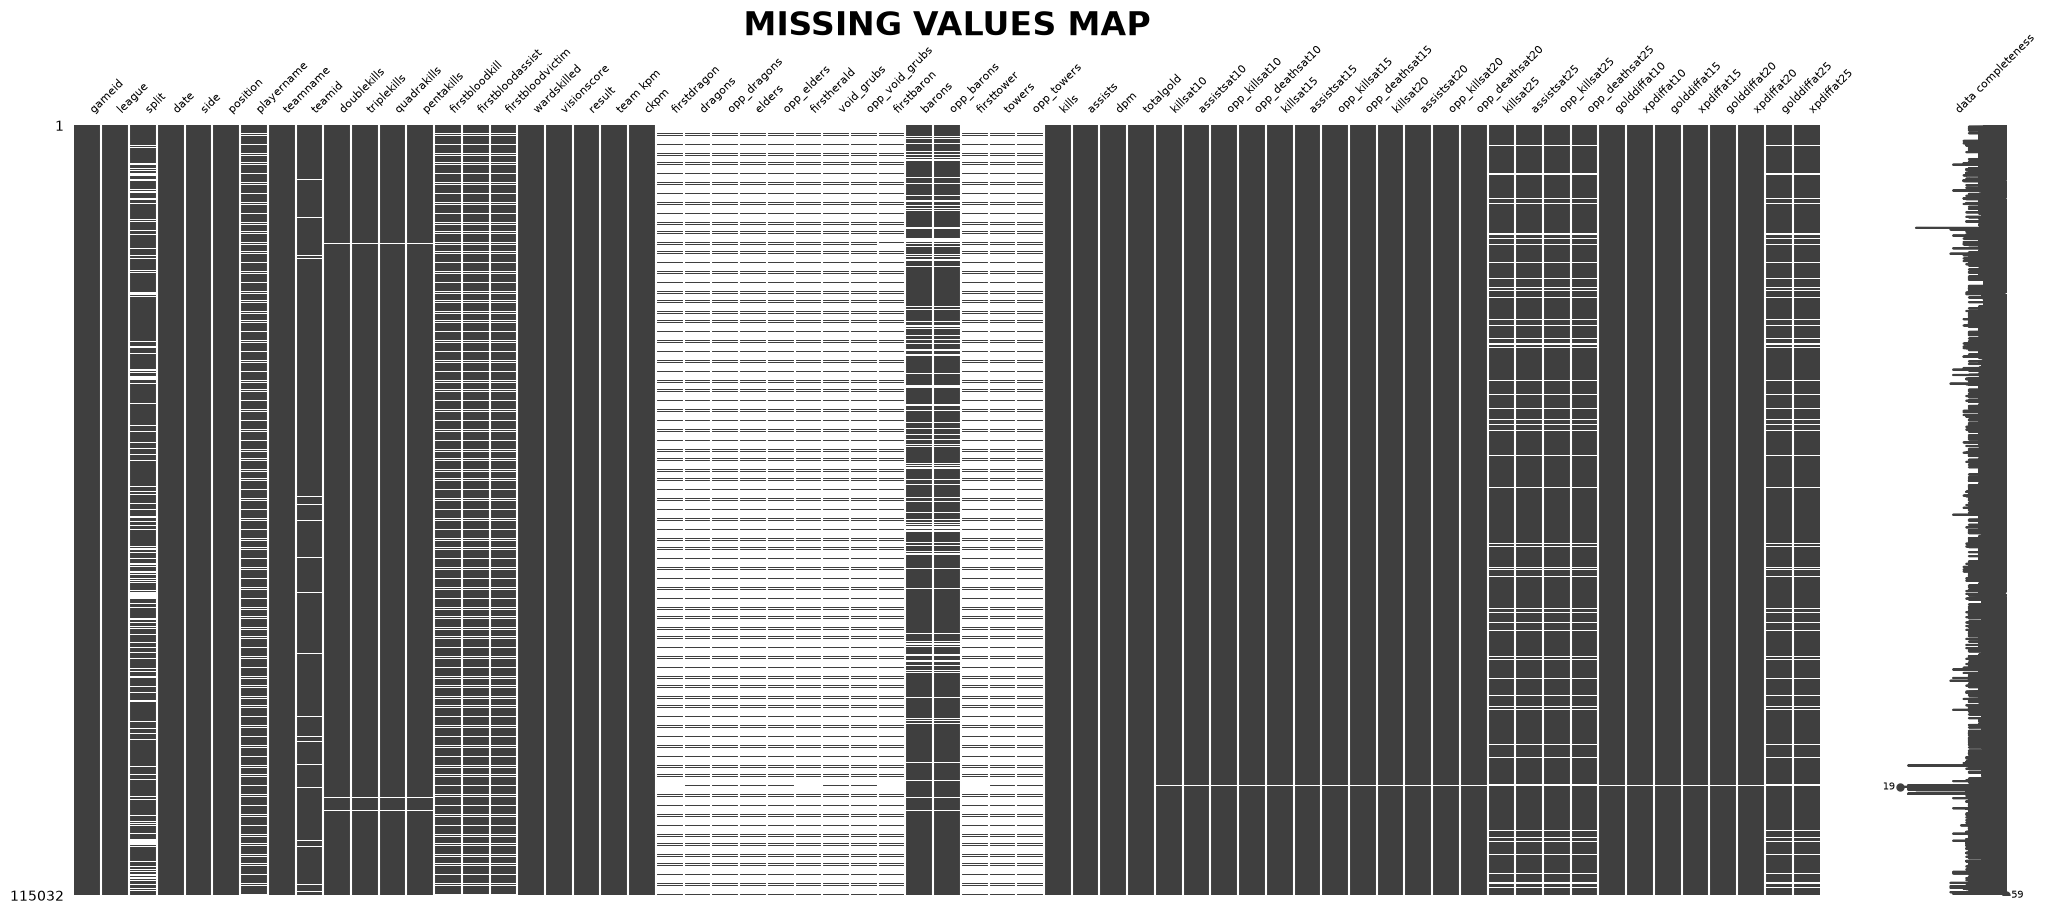


------------- MISSING VALUES REPORT --------------
                  Count   (%)
firstbaron        96012 83.47
firstherald       95886 83.36
firsttower        95878 83.35
firstdragon       95880 83.35
opp_elders        95870 83.34
elders            95870 83.34
opp_dragons       95860 83.33
dragons           95860 83.33
void_grubs        95860 83.33
opp_void_grubs    95860 83.33
towers            95860 83.33
opp_towers        95860 83.33
firstbloodassist  19262 16.74
firstbloodvictim  19262 16.74
split             19260 16.74
firstbloodkill    19252 16.74
playername        19172 16.67
barons            14090 12.25
opp_barons        14090 12.25
killsat25          8484  7.38
opp_killsat25      8484  7.38
assistsat25        8484  7.38
golddiffat25       8484  7.38
xpdiffat25         8484  7.38
opp_deathsat25     8484  7.38
teamid             3246  2.82
golddiffat20        468  0.41
xpdiffat20          468  0.41
killsat20           468  0.41
assistsat20         468  0.41
opp_killsat20     

In [8]:
null_map(df)

In [9]:
data_profiling(df)

List of Columns: Index(['gameid', 'league', 'split', 'date', 'side', 'position', 'playername',
       'teamname', 'teamid', 'doublekills', 'triplekills', 'quadrakills',
       'pentakills', 'firstbloodkill', 'firstbloodassist', 'firstbloodvictim',
       'wardskilled', 'visionscore', 'result', 'team kpm', 'ckpm',
       'firstdragon', 'dragons', 'opp_dragons', 'elders', 'opp_elders',
       'firstherald', 'void_grubs', 'opp_void_grubs', 'firstbaron', 'barons',
       'opp_barons', 'firsttower', 'towers', 'opp_towers', 'kills', 'assists',
       'dpm', 'totalgold', 'killsat10', 'assistsat10', 'opp_killsat10',
       'opp_deathsat10', 'killsat15', 'assistsat15', 'opp_killsat15',
       'opp_deathsat15', 'killsat20', 'assistsat20', 'opp_killsat20',
       'opp_deathsat20', 'killsat25', 'assistsat25', 'opp_killsat25',
       'opp_deathsat25', 'golddiffat10', 'xpdiffat10', 'golddiffat15',
       'xpdiffat15', 'golddiffat20', 'xpdiffat20', 'golddiffat25',
       'xpdiffat25'],
      dtype='s

gameid                9586
league                  42
split                   16
date                  9166
side                     2
position                 6
playername            2777
teamname               412
teamid                 354
doublekills             12
triplekills              5
quadrakills              4
pentakills               3
firstbloodkill           2
firstbloodassist         2
firstbloodvictim         2
wardskilled            123
visionscore            597
result                   2
team kpm              8249
ckpm                  6181
firstdragon              2
dragons                  8
opp_dragons              8
elders                   5
opp_elders               5
firstherald              2
void_grubs               5
opp_void_grubs           5
firstbaron               2
barons                   5
opp_barons               5
firsttower               2
towers                  18
opp_towers              18
kills                   54
assists                108
d


--------- UNIQUE VALUES OF OBJECT SERIES ---------

 league
LPL          6576
EM           6228
LAS          6120
LCK          6024
LCKC         5892
LEC          4596
LJL          4356
AL           4200
PRM          3864
CBLOL        3588
LCP          3396
LCS          3396
NACL         3372
LIT          3360
LFL          3300
ROL          3132
CD           3096
HLL          2820
EWC          2784
TCL          2628
EBL          2556
RL           2532
NLC          2520
LES          2496
HC           2412
LRS          2244
LRN          2112
HM           2088
LPLOL        1944
VCS          1860
NL           1788
HW           1236
PCS          1032
WSCI         1020
MSI           852
AM            756
KeSPA Cup     732
FST           540
CCWS          480
DCGI          468
WLDs          408
AC            228
Name: count, dtype: int64

 split
Summer        21960
Spring        21552
Winter        10836
Split 2        8424
Split 1        7692
Rounds 1-2     5340
Rounds 3-4     3672
Champ 2  

In [10]:
count_outliers(df, nunique_below3)


----- OUTLIER COUNTS AND PERCENTAGES PER COL -----
            Column  Count   (%)
0           barons  19691 17.12
1       opp_barons  19691 17.12
2        totalgold  19155 16.65
3              dpm  16711 14.53
4          assists  10868  9.45
5      wardskilled  10863  9.44
6      triplekills   9901  8.61
7   opp_deathsat20   8984  7.81
8      assistsat20   8729  7.59
9      assistsat25   8352  7.26
10  opp_deathsat25   8231  7.16
11     visionscore   8212  7.14
12           kills   7117  6.19
13   opp_killsat10   6415  5.58
14       killsat10   6415  5.58
15     assistsat15   6372  5.54
16    golddiffat20   6176  5.37
17      xpdiffat25   6060  5.27
18       killsat20   6004  5.22
19   opp_killsat20   6004  5.22
20    golddiffat25   6000  5.22
21  opp_deathsat10   5859  5.09
22       killsat15   5723  4.98
23   opp_killsat15   5723  4.98
24    golddiffat15   5712  4.97
25  opp_deathsat15   5437  4.73
26       killsat25   5200  4.52
27   opp_killsat25   5200  4.52
28      xpdiffat20  

# Data Visualisation

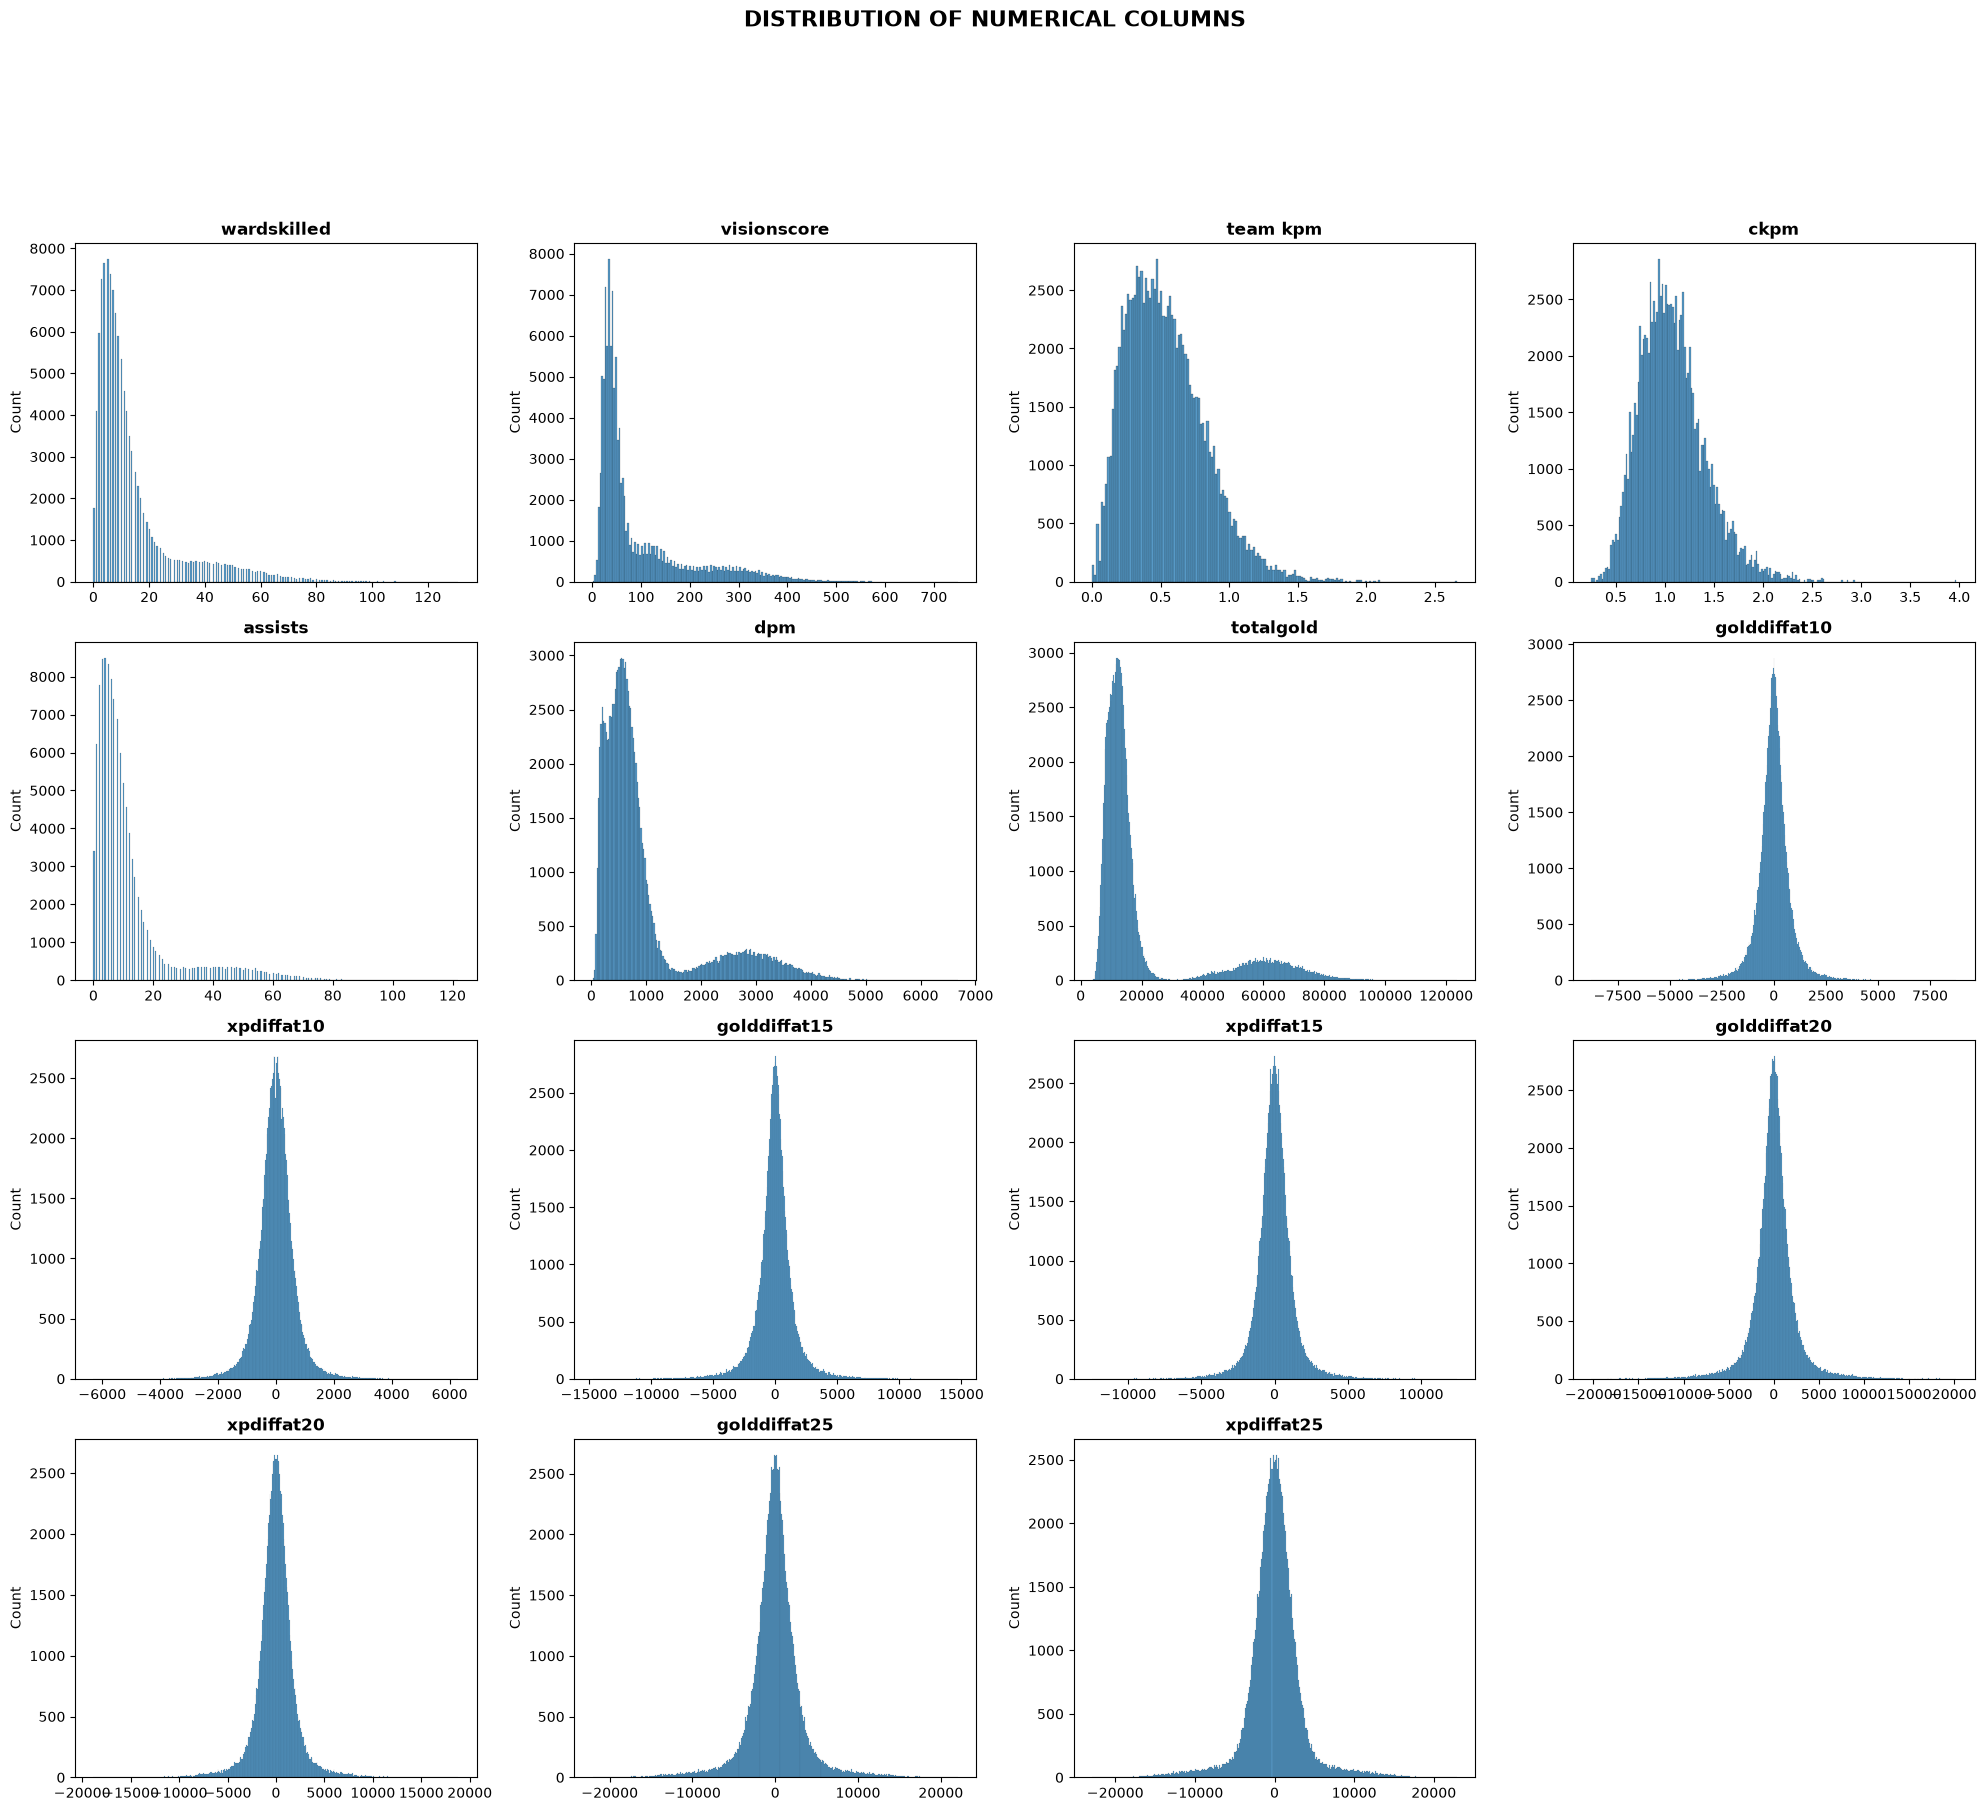

In [11]:
visualize_num_distribution(df, nunique_below100, nrows=20, ncols=4, figsize=(20, 80))

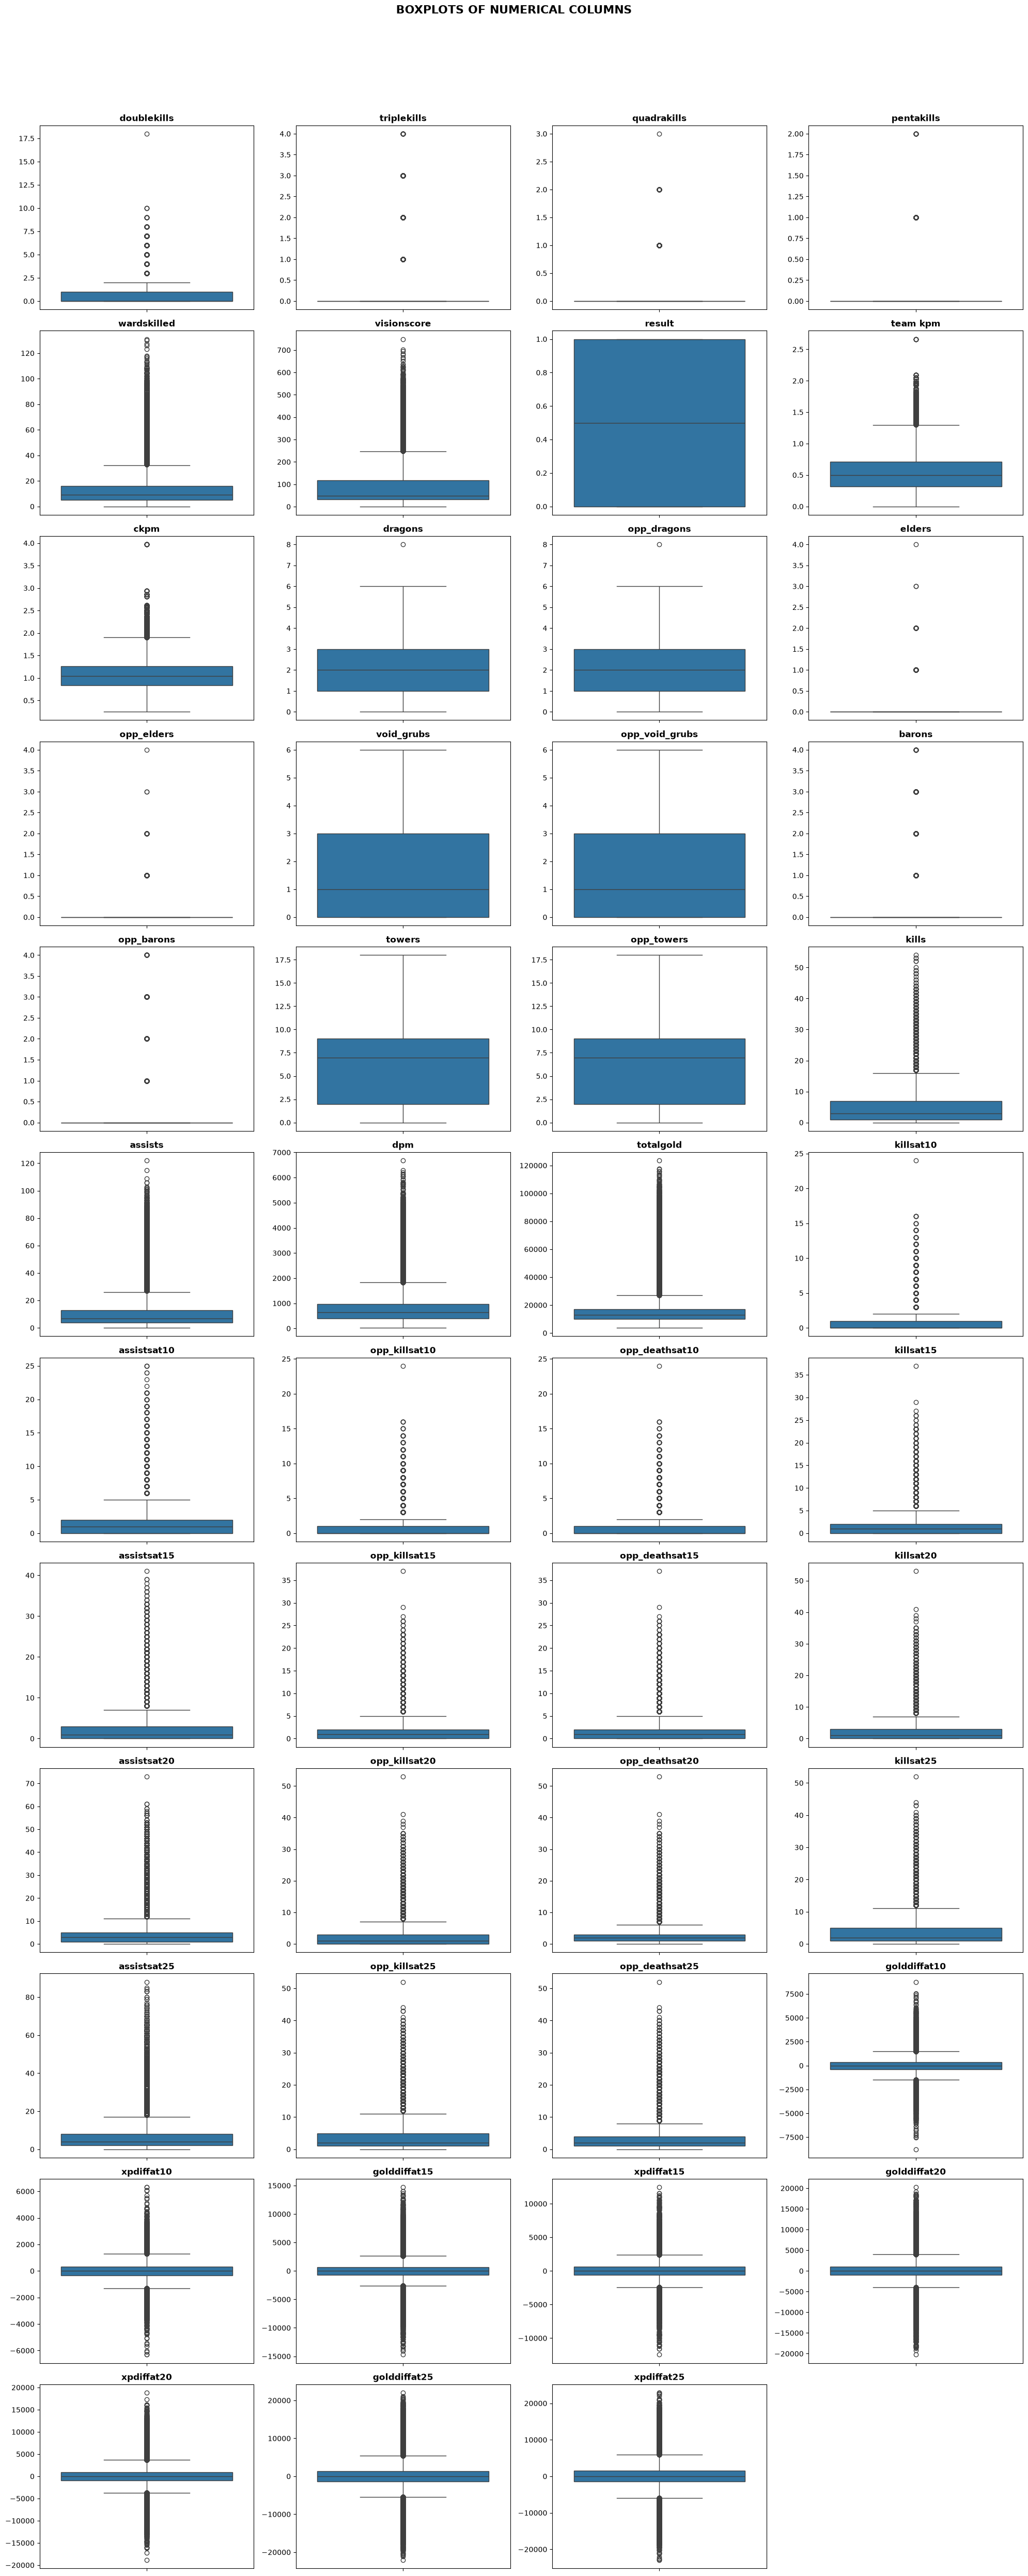

In [12]:
visualize_outliers(df, nunique_below3, nrows=20, ncols=4, figsize=(20, 80))

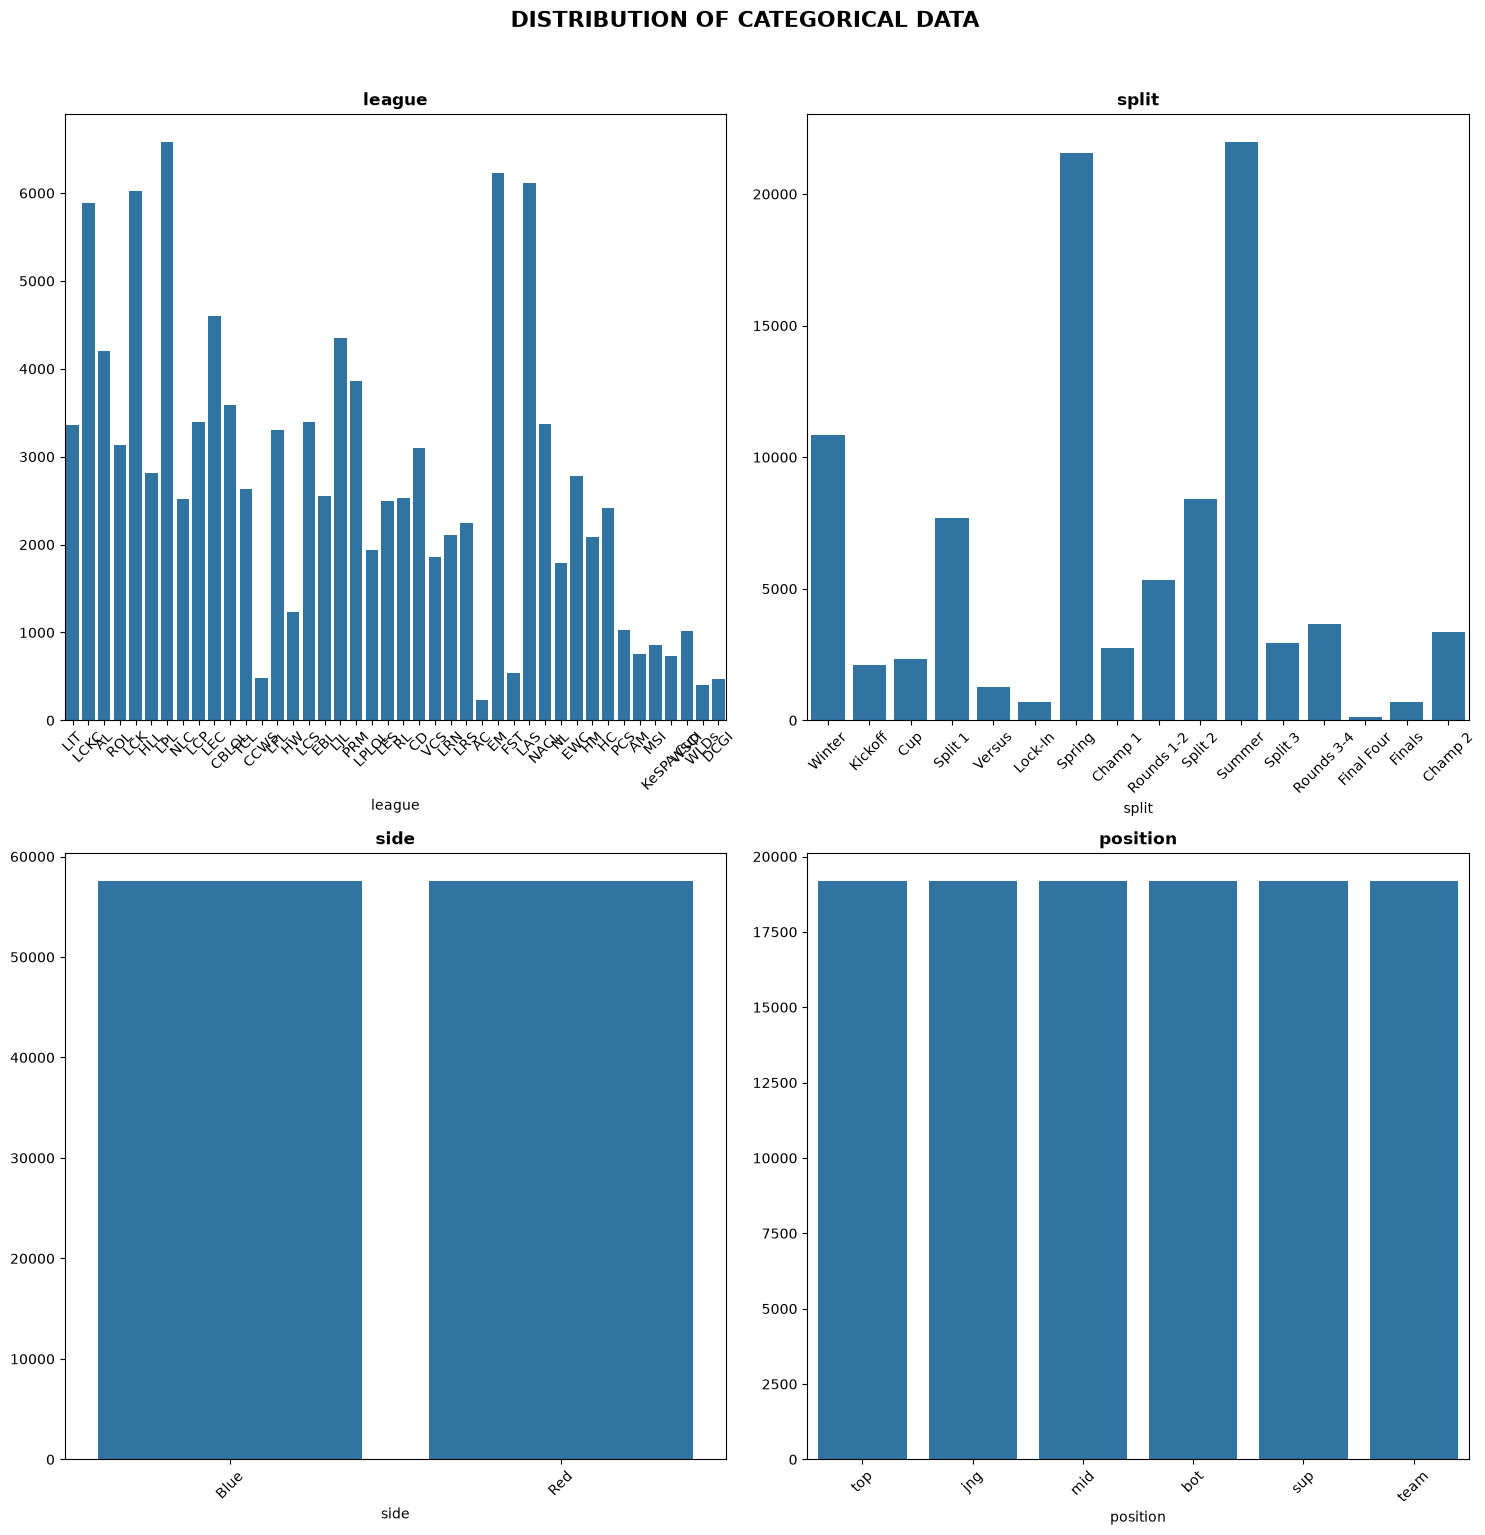

In [13]:
visualize_cat_distribution(df, catcols_to_drop, nrows=2, ncols=2)

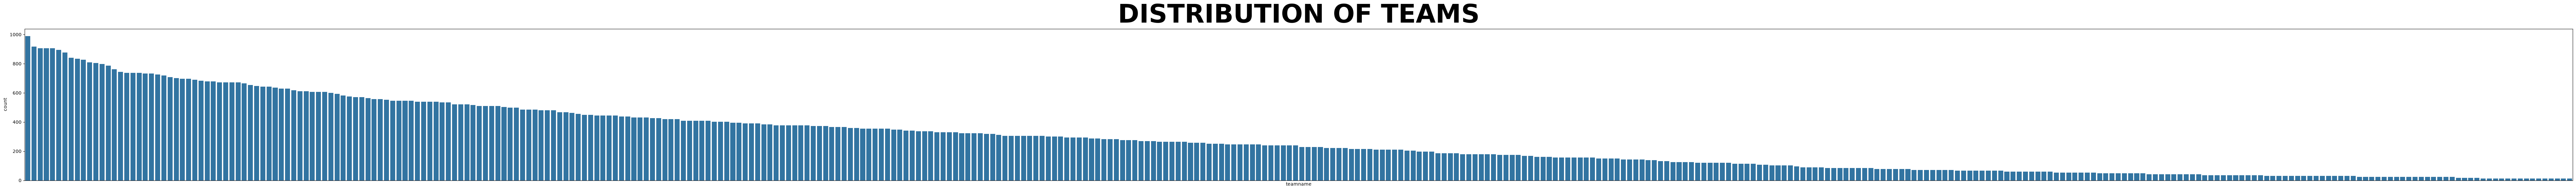

In [14]:
# Visualization for team names distribution
team_order = df["teamname"].value_counts().index
plt.figure(figsize=(100, 6))
sns.countplot(data=df, x='teamname', order=team_order)
plt.title('DISTRIBUTION OF TEAMS', fontsize=56, fontweight="bold")
plt.xticks([], [])
plt.show()

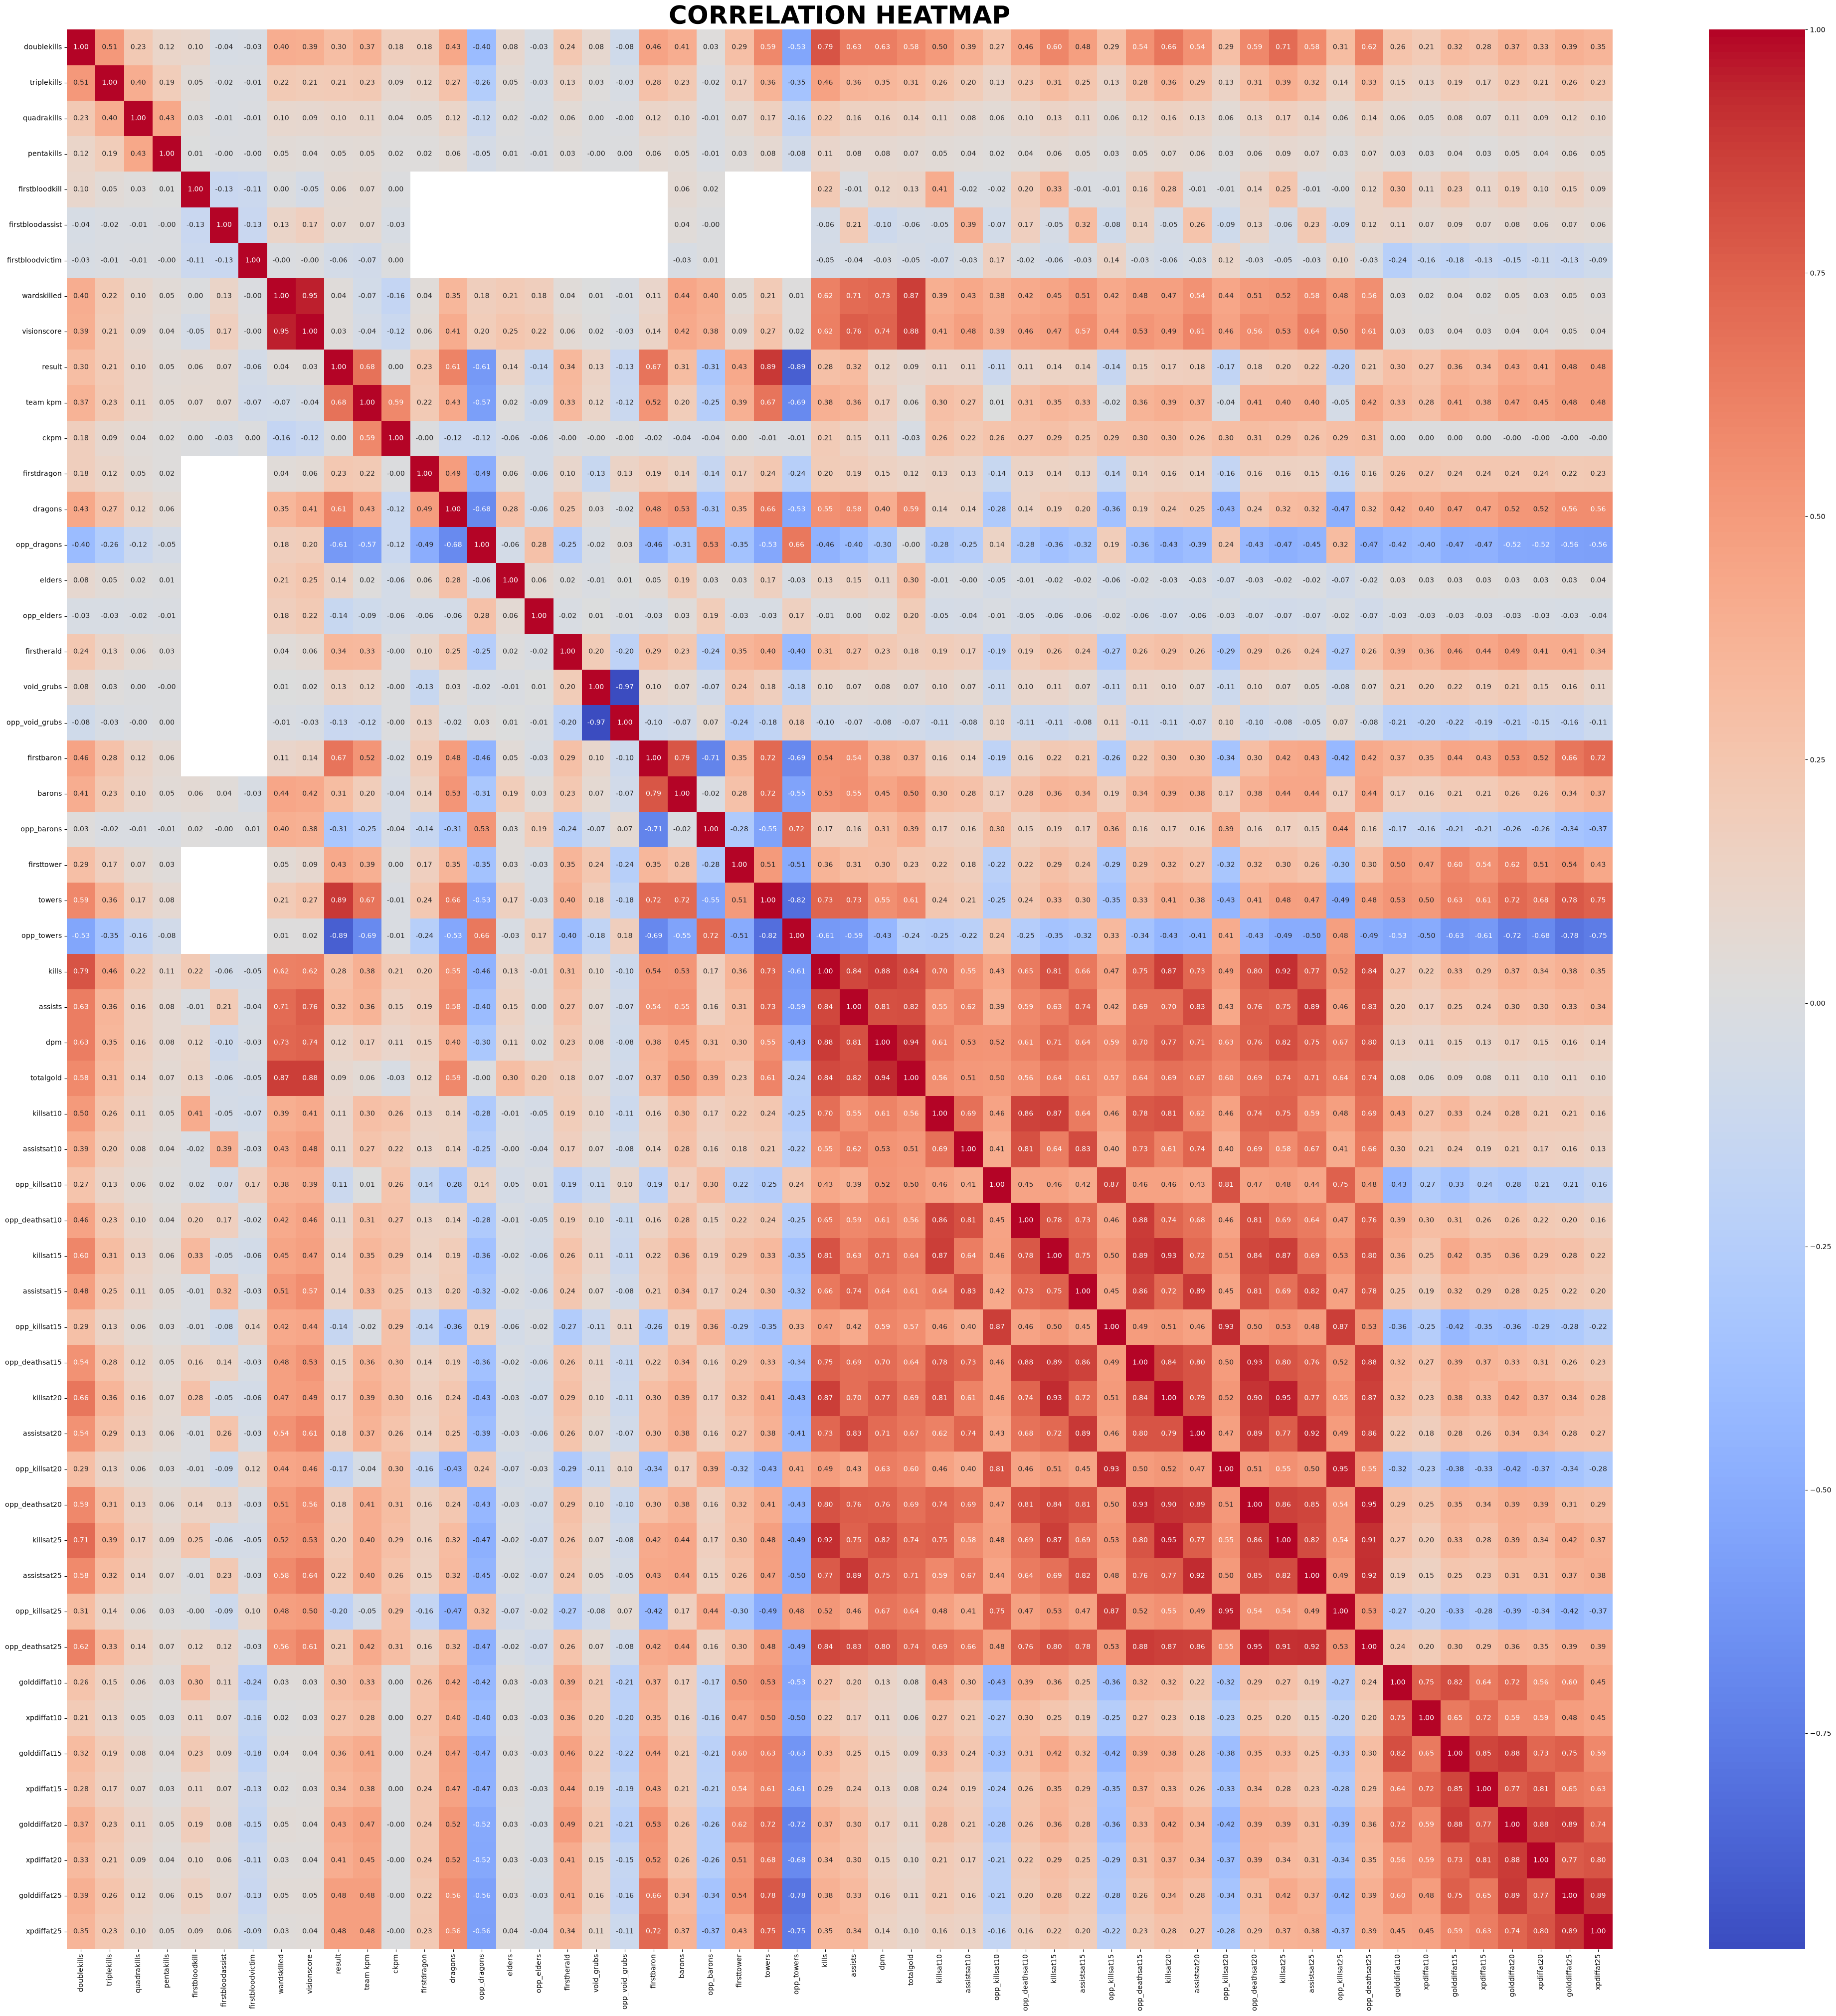

In [16]:
# Compute correlation matrix
corr_mtx = df.corr(numeric_only=True)

# Plot correlation heatmap
plt.figure(figsize=(50, 50))
sns.heatmap(corr_mtx, cmap='coolwarm', annot=True, fmt='.2f')
plt.title('CORRELATION HEATMAP', fontsize=36, fontweight="bold")
plt.show()